# Phishing URL — Multi-Model Comparison



In [1]:
# 1. Imports
import warnings
warnings.filterwarnings("ignore")
import re, math, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from urllib.parse import urlparse
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, average_precision_score
)
print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# 2. Load dataset
df = pd.read_csv("phishing.csv")
df.columns = df.columns.str.lower().str.strip()
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (235795, 56)


,filename,url,urllength,domain,domainlength,isdomainip,tld,urlsimilarityindex,charcontinuationrate,tldlegitimateprob,...,pay,crypto,hascopyrightinfo,noofimage,noofcss,noofjs,noofselfref,noofemptyref,noofexternalref,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [3]:
# 3. Clean dataset and target
if "url" not in df.columns or "label" not in df.columns:
    raise ValueError("phishing.csv must contain 'url' and 'label' columns.")
df = df.dropna(subset=["url", "label"]).drop_duplicates(subset=["url"])
df["target"] = df["label"].astype(int)
if not set(df["target"].unique()).issubset({0,1}):
    raise ValueError("Labels must be binary 0/1.")
print("Rows after cleaning:", len(df))
print("Label distribution:")
display(df["target"].value_counts().rename(index={0:"Legitimate",1:"Phishing"}))


Rows after cleaning: 235370
Label distribution:


target
Phishing      134850
Legitimate    100520
Name: count, dtype: int64

In [4]:
# 4. URL feature extraction
def extract_features(url):
    url = str(url)
    lower = url.lower()

    parsed = urlparse(url)

    domain = parsed.netloc
    path = parsed.path
    query = parsed.query

    L = len(url)
    DL = len(domain)

    # HTTPS
    https = int(parsed.scheme.lower() == "https")

    # IP address detection
    try:
        ipaddress.ip_address(domain.split(":")[0])
        is_ip = 1
    except:
        is_ip = 0

    # Subdomain count
    parts = domain.split(".")
    subdomains = max(0, len(parts) - 2)

    # Obfuscation
    obf_chars = sum(
        url.count(c)
        for c in ["%", "\\", "@"]
    )

    obf = int(obf_chars > 0)

    # Character statistics
    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)

    special_chars = [
        "-", "_", "@", "#", "%", ";", ":"
    ]

    special = sum(url.count(c) for c in special_chars)

    # Continuation rate
    continuation = (
        sum(c in "/\\" for c in url) / L
        if L else 0
    )

    # TLD
    tld = parts[-1] if len(parts) > 1 else ""

    # Suspicious keywords
    words = [
        "login",
        "verify",
        "verification",
        "secure",
        "account",
        "update",
        "password",
        "signin",
        "bank",
        "confirm",
        "paypal",
        "free",
        "bonus",
        "wallet",
        "recover"
    ]

    suspicious_keyword_count = sum(
        w in lower for w in words
    )

    # FIXED entropy function
    def entropy(s):
        if not s:
            return 0

        counts = {}
        for c in s:
            counts[c] = counts.get(c, 0) + 1

        total = len(s)
        result = 0

        for count in counts.values():
            p = count / total
            result -= p * math.log2(p)

        return result

    return {
        "url_length": L,
        "domain_length": DL,
        "is_domain_ip": is_ip,
        "no_of_subdomain": subdomains,

        "has_obfuscation": obf,
        "no_of_obfuscated_char": obf_chars,
        "obfuscation_ratio": obf_chars / L if L else 0,

        "no_of_letters": letters,
        "letter_ratio": letters / L if L else 0,

        "no_of_digits": digits,
        "digit_ratio": digits / L if L else 0,

        "no_of_equals": url.count("="),
        "no_of_qmark": url.count("?"),
        "no_of_ampersand": url.count("&"),

        "no_of_other_special_chars": special,
        "special_char_ratio": special / L if L else 0,

        "is_https": https,

        "no_of_slashes": url.count("/"),
        "no_of_dots": url.count("."),
        "no_of_hyphens": url.count("-"),

        "continuation_rate": continuation,
        "tld_length": len(tld),

        "suspicious_keyword_count": suspicious_keyword_count,

        "domain_entropy": entropy(domain),
        "url_entropy": entropy(url)
    }

In [5]:
X = pd.DataFrame([
    extract_features(u)
    for u in df["url"]
])

X = X.replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Feature shape: (235370, 25)
Target shape: (235370,)


,url_length,domain_length,is_domain_ip,no_of_subdomain,has_obfuscation,no_of_obfuscated_char,obfuscation_ratio,no_of_letters,letter_ratio,no_of_digits,...,special_char_ratio,is_https,no_of_slashes,no_of_dots,no_of_hyphens,continuation_rate,tld_length,suspicious_keyword_count,domain_entropy,url_entropy
0,32,24,0,1,0,0,0.0,27,0.843750,0,...,0.031250,1,2,2,0,0.062500,3,1,3.657268,3.929229
1,24,16,0,1,0,0,0.0,18,0.750000,0,...,0.083333,1,2,2,1,0.083333,2,0,3.327820,3.970176
2,30,22,0,2,0,0,0.0,24,0.800000,0,...,0.033333,1,2,3,0,0.066667,2,0,3.629220,4.164735
3,27,19,0,1,0,0,0.0,22,0.814815,0,...,0.037037,1,2,2,0,0.074074,3,0,3.576618,4.060262
4,34,26,0,1,0,0,0.0,29,0.852941,0,...,0.029412,1,2,2,0,0.058824,3,0,3.430457,3.917626


In [6]:
# 6. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", X_train.shape, " Testing:", X_test.shape)


Training: (188296, 25)  Testing: (47074, 25)


In [7]:
# 7. Define models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Linear SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearSVC(C=1.0, max_iter=5000, random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=15, min_samples_split=5, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=20, min_samples_split=5,
        n_jobs=-1, random_state=42
    ),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=100, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", n_jobs=-1, random_state=42
    )
}
print(*models.keys(), sep="\n")


Logistic Regression
Linear SVM
Decision Tree
Random Forest
XGBoost


In [8]:
# 8. Train and evaluate all models
results=[]; trained_models={}; prediction_data={}
for name, model in models.items():
    print("Training:", name)
    start=time.time()
    model.fit(X_train,y_train)
    elapsed=time.time()-start
    pred=model.predict(X_test)
    score=model.predict_proba(X_test)[:,1] if hasattr(model,"predict_proba") else model.decision_function(X_test)
    results.append({
        "Model":name,
        "Accuracy":accuracy_score(y_test,pred),
        "Precision":precision_score(y_test,pred,zero_division=0),
        "Recall":recall_score(y_test,pred,zero_division=0),
        "F1 Score":f1_score(y_test,pred,zero_division=0),
        "ROC-AUC":roc_auc_score(y_test,score),
        "PR-AUC":average_precision_score(y_test,score),
        "Training Time (s)":elapsed
    })
    trained_models[name]=model
    prediction_data[name]={"y_pred":pred,"y_score":score}
results_df=pd.DataFrame(results).sort_values("F1 Score",ascending=False).reset_index(drop=True)
display(results_df.round(4))


Training: Logistic Regression
Training: Linear SVM
Training: Decision Tree
Training: Random Forest
Training: XGBoost


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Training Time (s)
0,XGBoost,0.9960,0.9937,0.9994,0.9965,0.9980,0.9973,6.1889
1,Random Forest,0.9959,0.9937,0.9993,0.9965,0.9980,0.9973,33.1262
2,Decision Tree,0.9956,0.9936,0.9988,0.9962,0.9961,0.9938,1.6763
3,Linear SVM,0.9940,0.9900,0.9996,0.9948,0.9975,0.9965,5.6990
4,Logistic Regression,0.9938,0.9900,0.9992,0.9946,0.9978,0.9973,2.2938


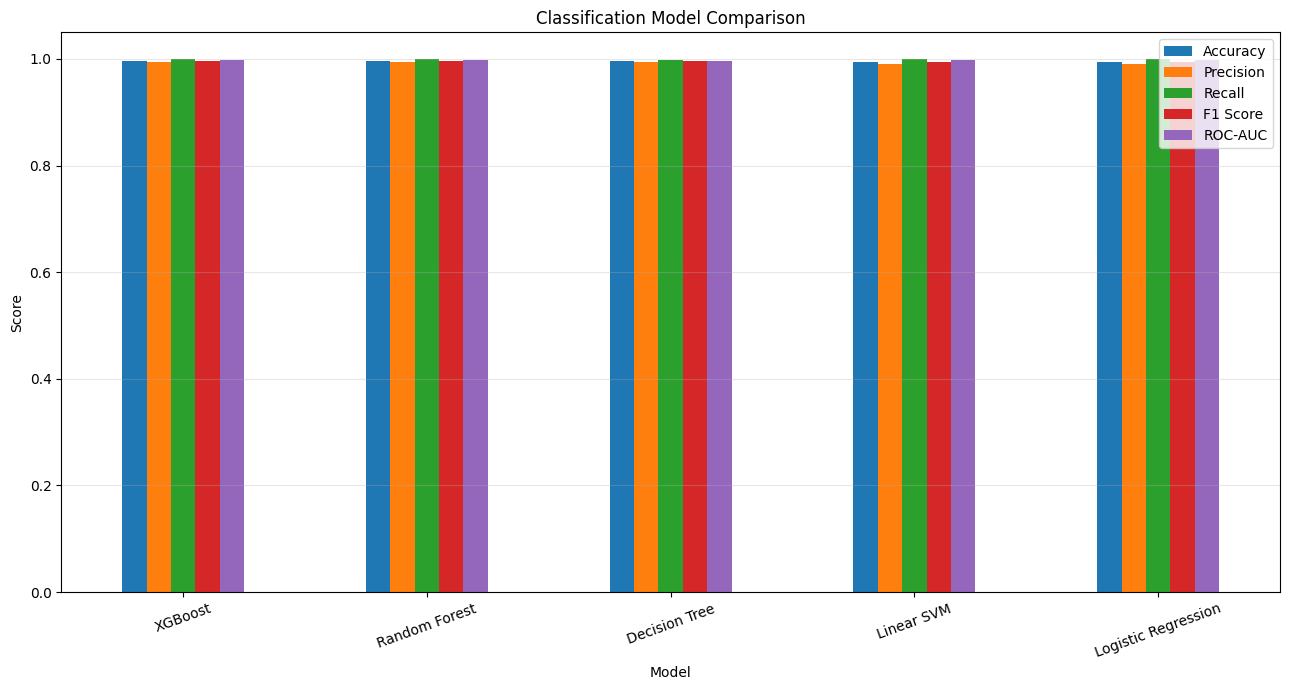

In [9]:
# 9. All-metric comparison graph
results_df.set_index("Model")[["Accuracy","Precision","Recall","F1 Score","ROC-AUC"]].plot(
    kind="bar", figsize=(13,7)
)
plt.title("Classification Model Comparison")
plt.xlabel("Model"); plt.ylabel("Score"); plt.ylim(0,1.05)
plt.xticks(rotation=20); plt.grid(axis="y",alpha=.3); plt.tight_layout(); plt.show()


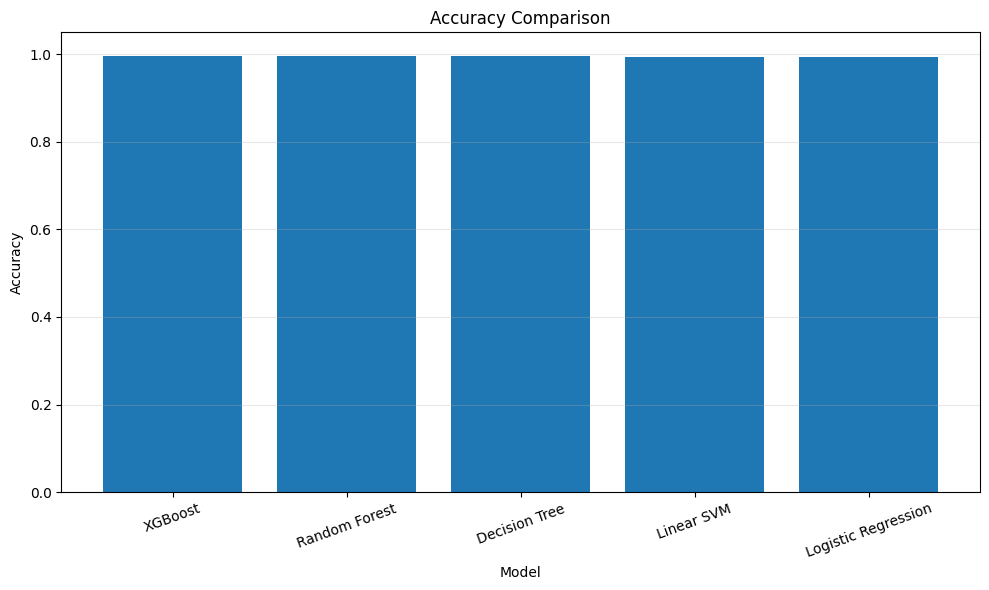

In [10]:
# 10. Accuracy comparison
plt.figure(figsize=(10,6))
plt.bar(results_df["Model"],results_df["Accuracy"])
plt.title("Accuracy Comparison"); plt.xlabel("Model"); plt.ylabel("Accuracy")
plt.ylim(0,1.05); plt.xticks(rotation=20); plt.grid(axis="y",alpha=.3)
plt.tight_layout(); plt.show()


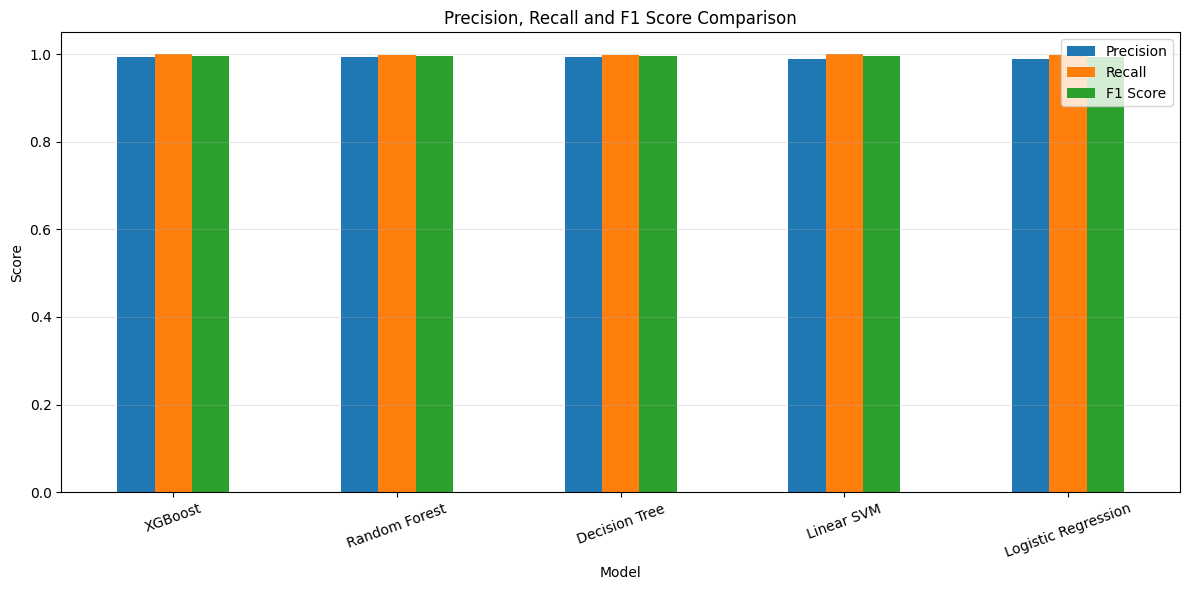

In [11]:
# 11. Precision, Recall, F1
results_df.set_index("Model")[["Precision","Recall","F1 Score"]].plot(
    kind="bar", figsize=(12,6)
)
plt.title("Precision, Recall and F1 Score Comparison")
plt.xlabel("Model"); plt.ylabel("Score"); plt.ylim(0,1.05)
plt.xticks(rotation=20); plt.grid(axis="y",alpha=.3); plt.tight_layout(); plt.show()


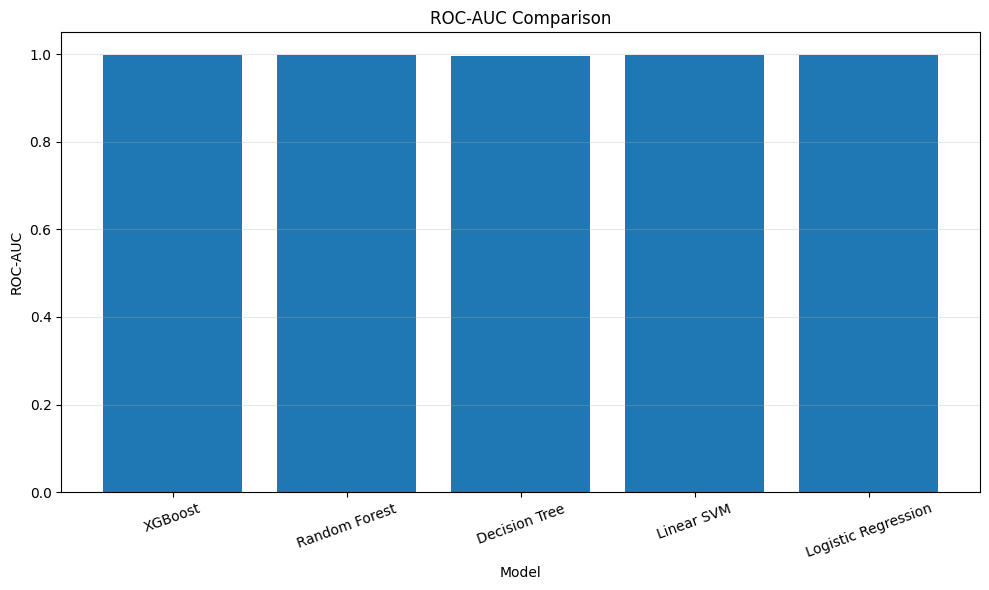

In [12]:
# 12. ROC-AUC comparison
plt.figure(figsize=(10,6))
plt.bar(results_df["Model"],results_df["ROC-AUC"])
plt.title("ROC-AUC Comparison"); plt.xlabel("Model"); plt.ylabel("ROC-AUC")
plt.ylim(0,1.05); plt.xticks(rotation=20); plt.grid(axis="y",alpha=.3)
plt.tight_layout(); plt.show()


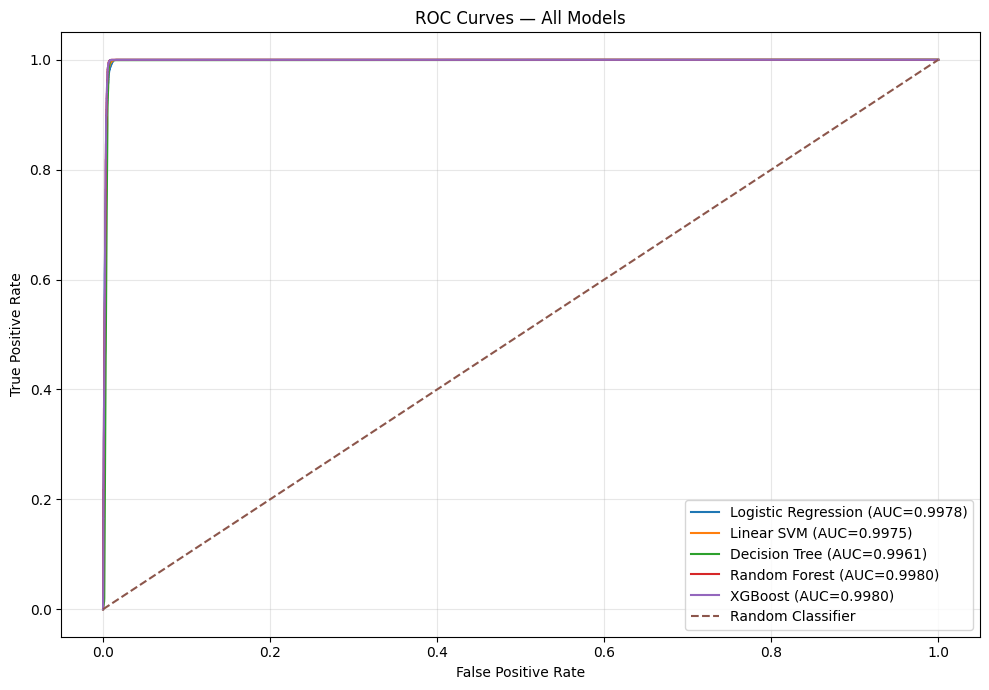

In [13]:
# 13. ROC curves
plt.figure(figsize=(10,7))
for name in models:
    score=prediction_data[name]["y_score"]
    fpr,tpr,_=roc_curve(y_test,score)
    auc=roc_auc_score(y_test,score)
    plt.plot(fpr,tpr,label=f"{name} (AUC={auc:.4f})")
plt.plot([0,1],[0,1],"--",label="Random Classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()


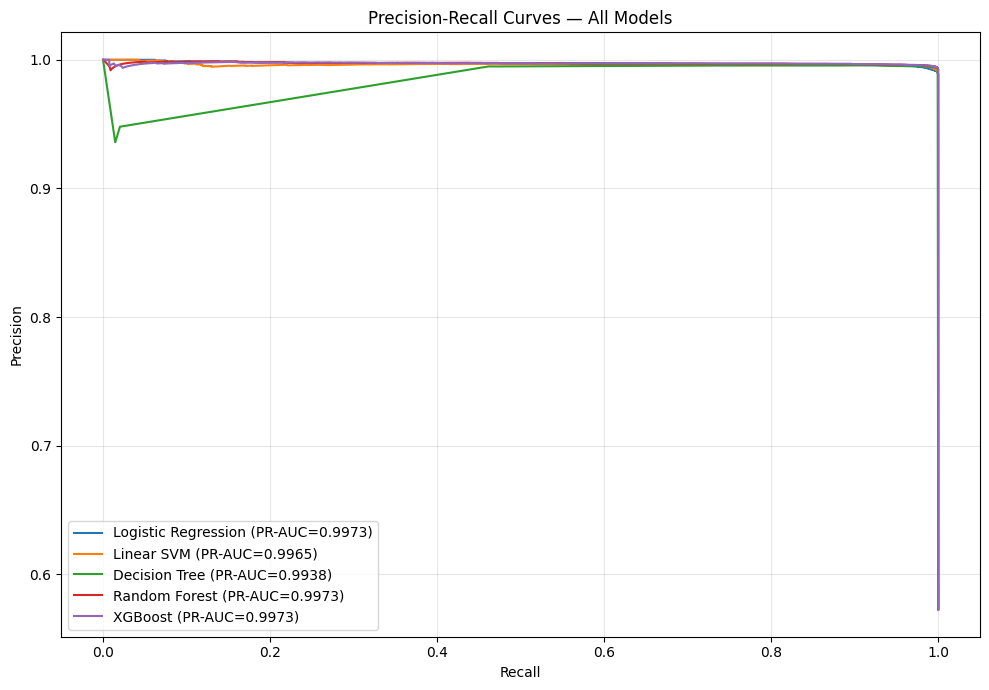

In [14]:
# 14. Precision-Recall curves
plt.figure(figsize=(10,7))
for name in models:
    score=prediction_data[name]["y_score"]
    precision,recall,_=precision_recall_curve(y_test,score)
    ap=average_precision_score(y_test,score)
    plt.plot(recall,precision,label=f"{name} (PR-AUC={ap:.4f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curves — All Models")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()


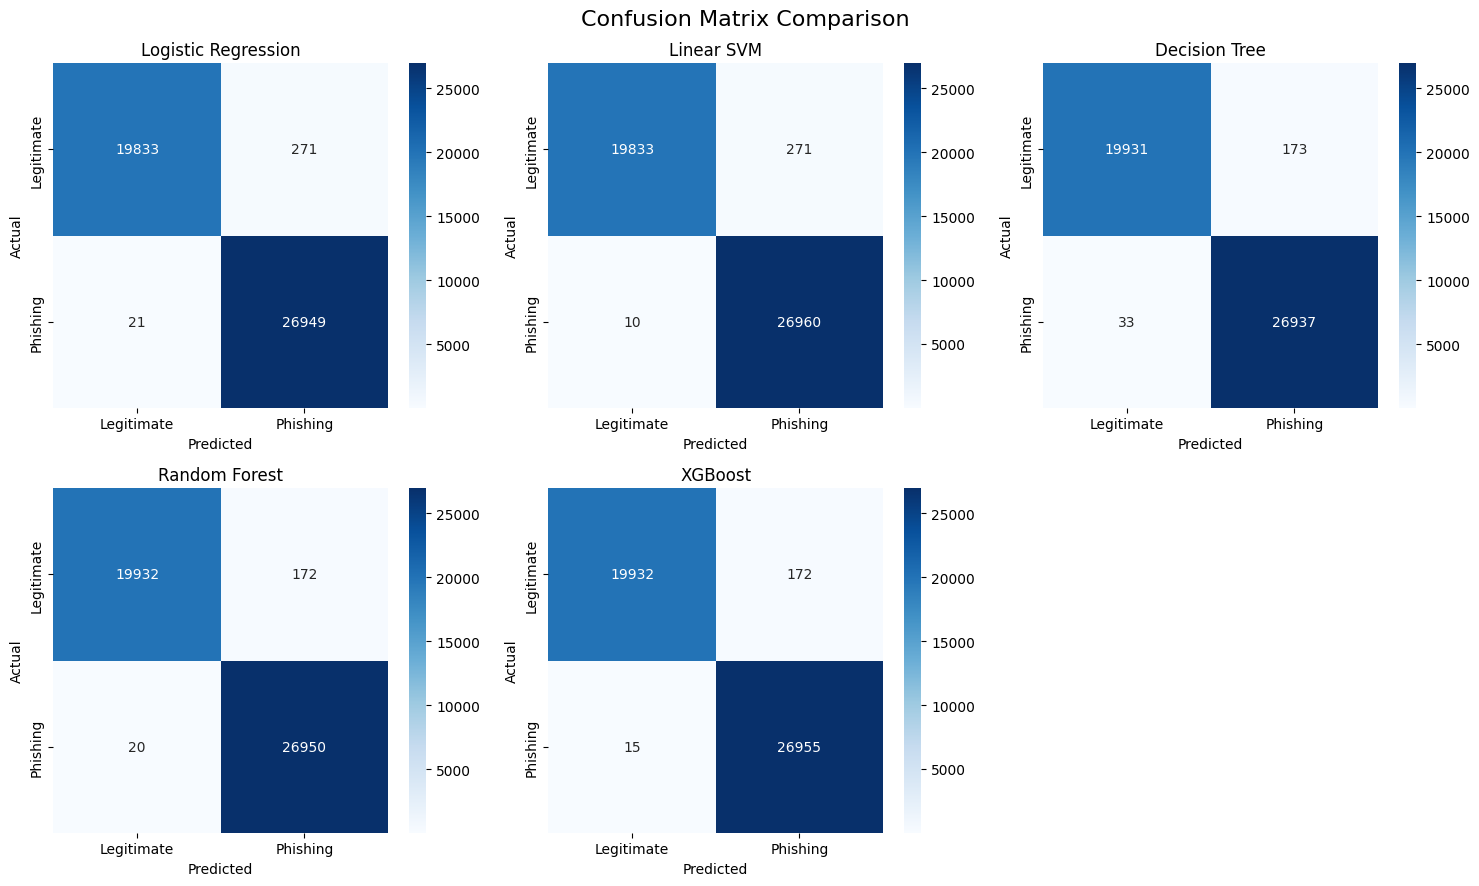

In [15]:
# 15. Confusion matrices — all models
fig,axes=plt.subplots(2,3,figsize=(15,9)); axes=axes.flatten()
for i,name in enumerate(models):
    cm=confusion_matrix(y_test,prediction_data[name]["y_pred"])
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",ax=axes[i],
                xticklabels=["Legitimate","Phishing"],
                yticklabels=["Legitimate","Phishing"])
    axes[i].set_title(name); axes[i].set_xlabel("Predicted"); axes[i].set_ylabel("Actual")
for j in range(len(models),len(axes)): axes[j].axis("off")
plt.suptitle("Confusion Matrix Comparison",fontsize=16)
plt.tight_layout(); plt.show()


In [16]:
# 16. Classification reports
for name in models:
    print("="*70, name, "="*70)
    print(classification_report(
        y_test,prediction_data[name]["y_pred"],
        target_names=["Legitimate","Phishing"],zero_division=0
    ))


====================================================================== Logistic Regression ======================================================================
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99     20104
    Phishing       0.99      1.00      0.99     26970

    accuracy                           0.99     47074
   macro avg       0.99      0.99      0.99     47074
weighted avg       0.99      0.99      0.99     47074

====================================================================== Linear SVM ======================================================================
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99     20104
    Phishing       0.99      1.00      0.99     26970

    accuracy                           0.99     47074
   macro avg       0.99      0.99      0.99     47074
weighted avg       0.99      0.99      0.99     47074

===============================

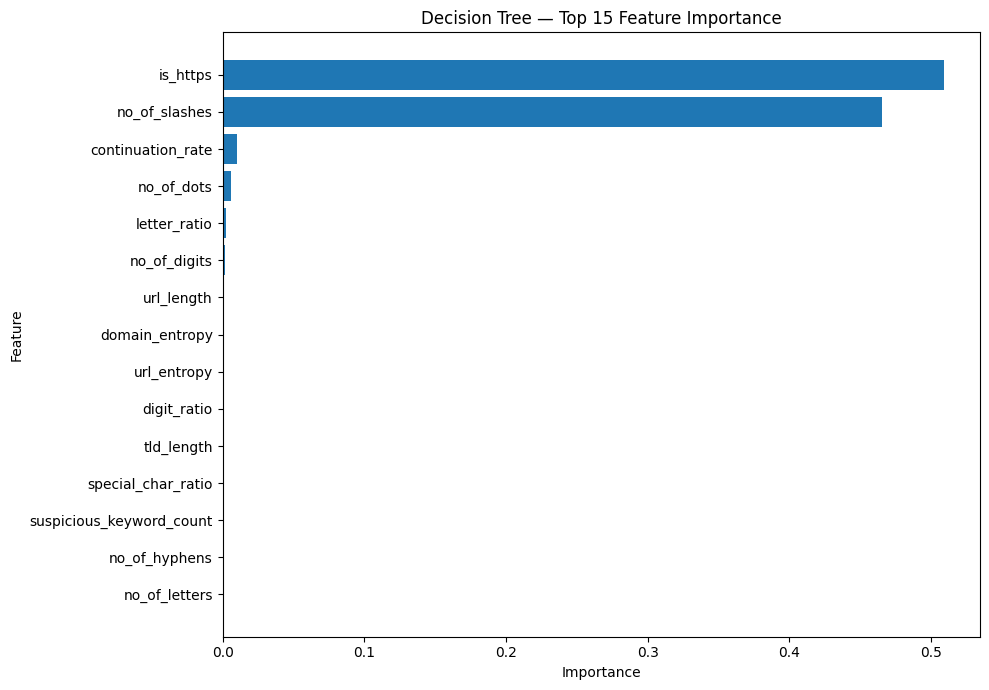

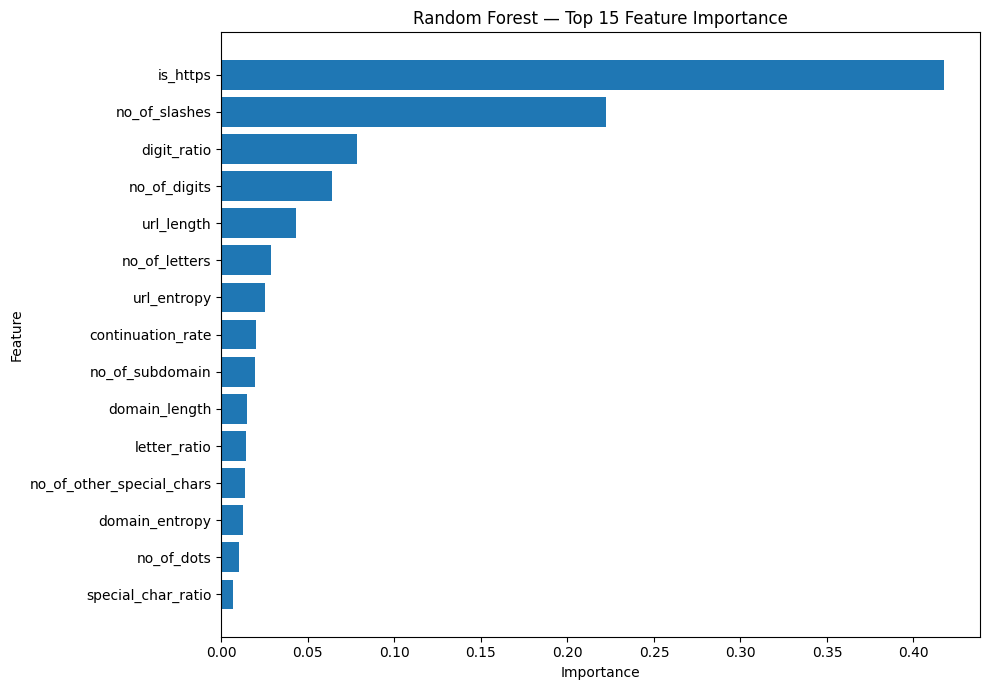

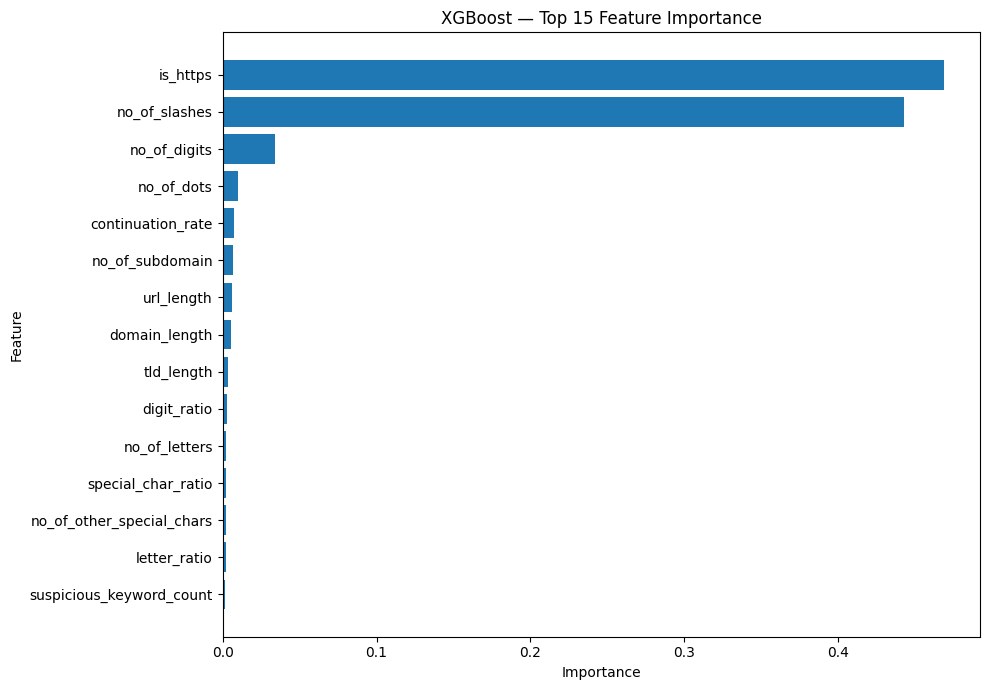

In [17]:
# 17. Feature importance — tree models
importance_tables={}
for name in ["Decision Tree","Random Forest","XGBoost"]:
    imp=pd.DataFrame({
        "Feature":X.columns,
        "Importance":trained_models[name].feature_importances_
    }).sort_values("Importance",ascending=False)
    importance_tables[name]=imp
    top=imp.head(15).sort_values("Importance")
    plt.figure(figsize=(10,7))
    plt.barh(top["Feature"],top["Importance"])
    plt.title(f"{name} — Top 15 Feature Importance")
    plt.xlabel("Importance"); plt.ylabel("Feature")
    plt.tight_layout(); plt.show()


,Feature,Decision Tree,Random Forest,XGBoost,Average
2,is_https,0.509207,0.417578,0.468736,0.465174
3,no_of_slashes,0.465381,0.222121,0.442805,0.376769
6,no_of_digits,0.001710,0.063971,0.034246,0.033309
12,digit_ratio,0.000681,0.078421,0.002758,0.027287
7,url_length,0.000924,0.042883,0.005824,0.016544
10,continuation_rate,0.010071,0.019845,0.007625,0.012514
0,no_of_letters,0.000214,0.028496,0.002417,0.010376
9,url_entropy,0.000759,0.025225,0.000909,0.008964
1,no_of_dots,0.006140,0.010210,0.010069,0.008806
11,no_of_subdomain,0.000201,0.019186,0.006727,0.008705


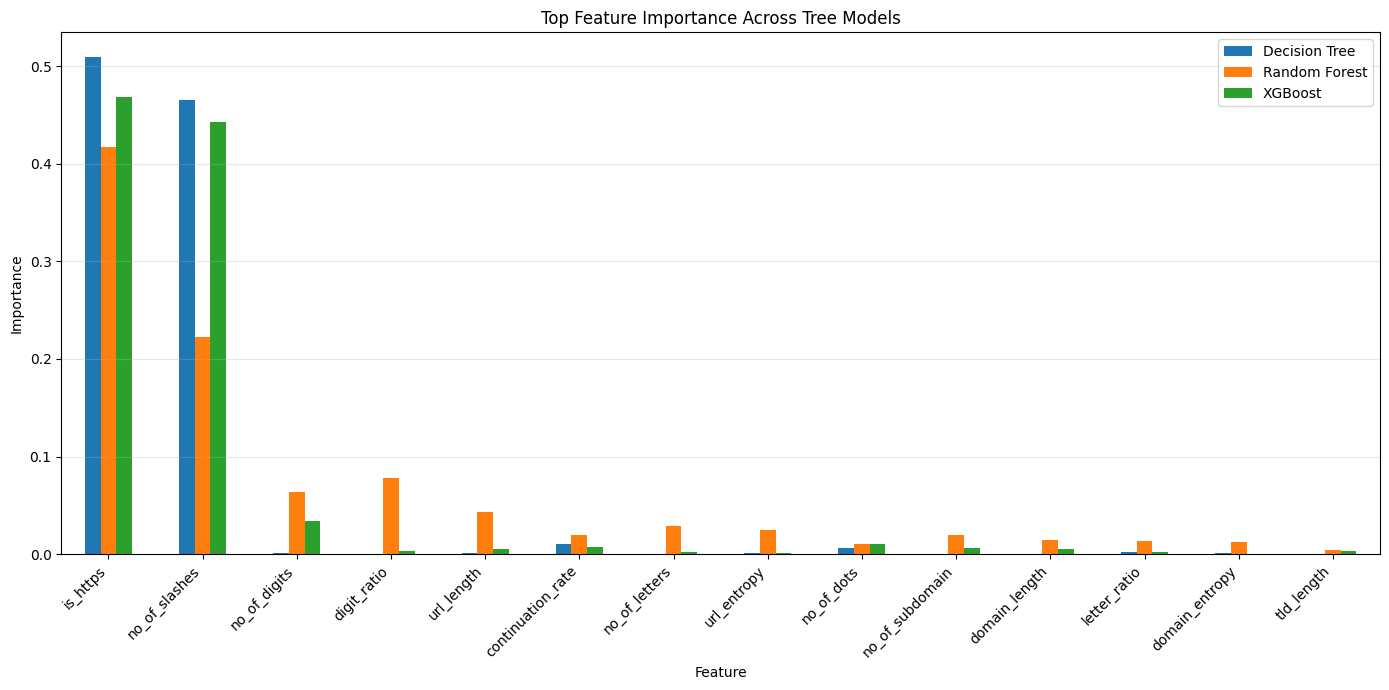

In [18]:
# 18. Feature-importance comparison
features=set()
for imp in importance_tables.values():
    features.update(imp.head(10)["Feature"])
fi=pd.DataFrame({"Feature":list(features)})
for name,imp in importance_tables.items():
    fi[name]=fi["Feature"].map(imp.set_index("Feature")["Importance"]).fillna(0)
fi["Average"]=fi[["Decision Tree","Random Forest","XGBoost"]].mean(axis=1)
fi=fi.sort_values("Average",ascending=False).head(15)
display(fi)
fi.set_index("Feature")[["Decision Tree","Random Forest","XGBoost"]].plot(
    kind="bar",figsize=(14,7)
)
plt.title("Top Feature Importance Across Tree Models")
plt.xlabel("Feature"); plt.ylabel("Importance")
plt.xticks(rotation=45,ha="right"); plt.grid(axis="y",alpha=.3)
plt.tight_layout(); plt.show()


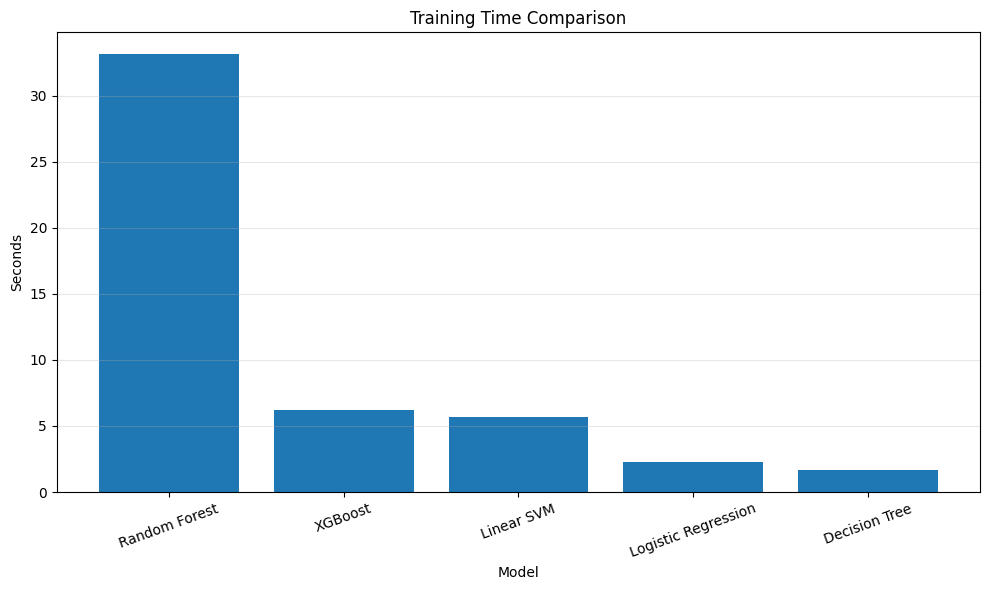

In [19]:
# 19. Training-time comparison
plt.figure(figsize=(10,6))
t=results_df.sort_values("Training Time (s)",ascending=False)
plt.bar(t["Model"],t["Training Time (s)"])
plt.title("Training Time Comparison"); plt.xlabel("Model"); plt.ylabel("Seconds")
plt.xticks(rotation=20); plt.grid(axis="y",alpha=.3); plt.tight_layout(); plt.show()


In [20]:
# 20. Final ranking
ranking=results_df.copy()
ranking["Overall Rank"]=ranking["F1 Score"].rank(ascending=False,method="min").astype(int)
ranking=ranking.sort_values("Overall Rank")
display(ranking[[
    "Overall Rank","Model","Accuracy","Precision","Recall",
    "F1 Score","ROC-AUC","PR-AUC","Training Time (s)"
]].round(4))
print("Best model by F1 Score:", ranking.iloc[0]["Model"])


,Overall Rank,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Training Time (s)
0,1,XGBoost,0.9960,0.9937,0.9994,0.9965,0.9980,0.9973,6.1889
1,2,Random Forest,0.9959,0.9937,0.9993,0.9965,0.9980,0.9973,33.1262
2,3,Decision Tree,0.9956,0.9936,0.9988,0.9962,0.9961,0.9938,1.6763
3,4,Linear SVM,0.9940,0.9900,0.9996,0.9948,0.9975,0.9965,5.6990
4,5,Logistic Regression,0.9938,0.9900,0.9992,0.9946,0.9978,0.9973,2.2938


Best model by F1 Score: XGBoost


In [21]:
# 21. Save comparison and all models
results_df.to_csv("model_comparison_results.csv",index=False)
joblib.dump(list(X.columns),"feature_names.pkl")
for name,model in trained_models.items():
    safe=name.lower().replace(" ","_").replace("-","")
    joblib.dump(model,f"{safe}_model.pkl")
best_name=ranking.iloc[0]["Model"]
safe=best_name.lower().replace(" ","_").replace("-","")
joblib.dump(trained_models[best_name],f"best_{safe}_model.pkl")
print("Saved model files and comparison CSV.")


Saved model files and comparison CSV.


In [22]:
# 22. Test best model on a new URL
test_url="https://www.google.com"
test_X=pd.DataFrame([extract_features(test_url)])[X.columns]
best_model=trained_models[best_name]
pred=int(best_model.predict(test_X)[0])
if hasattr(best_model,"predict_proba"):
    score=float(best_model.predict_proba(test_X)[0,1])
else:
    d=float(best_model.decision_function(test_X)[0])
    score=float(1/(1+np.exp(-d)))
print("="*60)
print("URL:",test_url)
print("Best model:",best_name)
print("Prediction:", "PHISHING" if pred==1 else "LEGITIMATE")
print(f"Phishing score: {score:.4f}")
print("="*60)


URL: https://www.google.com
Best model: XGBoost
Prediction: PHISHING
Phishing score: 0.9977


In [23]:
# 23. Export final summary
ranking.to_csv("final_model_comparison.csv",index=False)
display(ranking.round(4))
print("Saved: final_model_comparison.csv")


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Training Time (s),Overall Rank
0,XGBoost,0.9960,0.9937,0.9994,0.9965,0.9980,0.9973,6.1889,1
1,Random Forest,0.9959,0.9937,0.9993,0.9965,0.9980,0.9973,33.1262,2
2,Decision Tree,0.9956,0.9936,0.9988,0.9962,0.9961,0.9938,1.6763,3
3,Linear SVM,0.9940,0.9900,0.9996,0.9948,0.9975,0.9965,5.6990,4
4,Logistic Regression,0.9938,0.9900,0.9992,0.9946,0.9978,0.9973,2.2938,5


Saved: final_model_comparison.csv
